<div align="center">

# 🌍💻 LangCode 2027 · Shared Task 1 · Starter Notebook
## 🗣️ Prompting with 🐯 TigerCoder-1B

**Multilingual Code Generation** · LangCode 2027, the First Language and Code Workshop (NAACL 2027)<br>
*One problem, 50 natural languages, one correct program*

[🏠 Task website](https://langcode2027.github.io/task1/) · [📦 Data](https://langcode2027.github.io/task1/data/) · [🚀 Participate](https://langcode2027.github.io/task1/participate/) · [🏆 Leaderboard](https://langcode2027.github.io/task1/leaderboard/) · [🧪 CodaBench](https://www.codabench.org/competitions/18470/)

</div>

---

👋 **Welcome!** This notebook takes you from nothing to a file you can submit on CodaBench, in one run. It shows everything on the **trial set** first, where all the tests are public, so you can see how the official scorer judges each solution. Then it writes your **dev** submission.

| Step | What happens |
|:--:|---|
| 🛠️ **1** | Install the six toolchains, load the libraries |
| 📦 **2** | Download the data and the official scorer |
| 📏 **3** | Understand Pass@1 and check the scorer on trial |
| 🐯 **4** | Load TigerCoder-1B and prompt it |
| 🧪 **5** | Solve the 100 trial tasks and score them, step by step |
| 🔬 **6** | Look at what passed and what failed |
| 📝 **7** | Solve the 500 dev tasks |
| 📤 **8** | Write, check and zip `submission.zip` |
| 🚀 **9** | Submit on CodaBench |

⚡ **Runtime:** a free Colab **T4 GPU** is enough (Runtime → Change runtime type → T4 GPU). A full run takes about 25 minutes, most of it spent writing the 500 dev solutions.

🔁 There is a twin notebook that does **fine-tuning**; both are on the [Data page](https://langcode2027.github.io/task1/data/).

## 🛠️ 1 · Setup

The scorer runs every solution in its own language, so we install the **six toolchains** the competition uses: 🐍 Python, 🟨 JavaScript (Node 22), ⚙️ C (gcc), 🐘 PHP, 💎 Ruby and 🌙 Lua. Python and gcc already come with Colab.

In [1]:
#@title 🛠️ Install the six language toolchains (about 1 minute)
import os, sys, re, json, time, random, shutil, subprocess, zipfile, urllib.request, warnings, logging
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN'] = '1'          # TigerCoder-1B is public: no Hugging Face token needed
os.environ['HF_HUB_VERBOSITY'] = 'error'; os.environ['TRANSFORMERS_VERBOSITY'] = 'error'
warnings.filterwarnings('ignore'); logging.getLogger('huggingface_hub').setLevel(logging.ERROR)

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode:
        print(r.stdout[-1500:], r.stderr[-1500:]); raise RuntimeError(f'failed: {cmd}')
    return r.stdout.strip()

if not shutil.which('php') or not shutil.which('ruby') or not shutil.which('lua5.4'):
    print('📥 installing PHP, Ruby and Lua ...')
    sh('apt-get -qq update && DEBIAN_FRONTEND=noninteractive apt-get -qq install -y php-cli ruby lua5.4 > /dev/null')
sh('ln -sf "$(command -v lua5.4)" /usr/local/bin/lua')
if not sh('node --version 2>/dev/null || true').startswith('v22'):
    print('📥 installing Node 22 ...')
    sh('curl -fsSL https://nodejs.org/dist/v22.11.0/node-v22.11.0-linux-x64.tar.xz | tar -xJ -C /usr/local --strip-components=1')
# the scorer runs solutions with a fixed PATH (/usr/local/bin:/usr/bin:/bin); Colab keeps its Node in /tools/node
for tool in ['node', 'php', 'ruby', 'gcc']:
    where = shutil.which(tool)
    if where and not os.path.exists(f'/usr/local/bin/{tool}') and not where.startswith(('/usr/bin', '/bin')):
        os.symlink(where, f'/usr/local/bin/{tool}')

VERSIONS = {'🐍 Python': 'python3 --version', '🟨 Node': 'node --version', '⚙️ gcc': 'gcc --version | head -1',
            '🐘 PHP': 'php --version | head -1', '💎 Ruby': 'ruby --version', '🌙 Lua': 'lua -v'}
for name, cmd in VERSIONS.items():
    print(f'✅ {name:10s} {sh(cmd + " 2>&1")[:60]}')

✅ 🐍 Python   Python 3.13.16
✅ 🟨 Node     v22.23.4
✅ ⚙️ gcc     gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
✅ 🐘 PHP      PHP 8.3.6 (cli) (built: Oct 19 2026 15:16:58) (NTS)
✅ 💎 Ruby     ruby 3.2.3 (2024-01-18 revision 52bb2ac0a6) [x86_64-linux-gn
✅ 🌙 Lua      Lua 5.4.6  Copyright (C) 1994-2023 Lua.org, PUC-Rio


In [2]:
#@title 📚 Load the libraries and check the GPU
import importlib.metadata as im
from packaging.version import Version
need = {'transformers': '4.56', 'accelerate': '0.30', **globals().get('EXTRA_PACKAGES', {})}

def version_of(pkg):
    try:
        return im.version(pkg)
    except im.PackageNotFoundError:
        return None

todo = [f'{p}>={v}' for p, v in need.items() if not version_of(p) or Version(version_of(p)) < Version(v)]
if todo:
    print('📥 pip install', *todo); sh(f'{sys.executable} -m pip install -q ' + ' '.join(f'"{x}"' for x in todo))
if 'peft' in need and version_of('torchao') and Version(version_of('torchao')) < Version('0.16'):
    sh(f'{sys.executable} -m pip uninstall -q -y torchao')   # recent PEFT refuses old torchao; LoRA does not need it

import torch, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, HTML, Markdown
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
assert torch.cuda.is_available(), '🚫 No GPU found: Runtime → Change runtime type → T4 GPU, then run again.'
GPU = torch.cuda.get_device_name(0)
# bfloat16 on Ampere or newer (A100, L4); a T4 only emulates it, so float32 is faster there. Gemma 3 overflows in float16.
DTYPE = torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float32
print(f'🎮 GPU: {GPU} · weights in {str(DTYPE).replace("torch.", "")}')

🎮 GPU: Tesla T4 · weights in float32


## 📦 2 · Data and scorer

Everything comes from the [Data page](https://langcode2027.github.io/task1/data/) of the task website:

| File | Tasks | Tests in the file | Used for |
|---|:--:|:--:|---|
| `trial.jsonl` | 100 | all 5 ✅ + a reference solution | learning, checking, scoring yourself |
| `dev.jsonl` | 500 | 2 of 5 👀 | **Development phase** submissions |
| `test.jsonl` | 1,000 | 2 of 5 👀 | **Test phase** submissions, from Jan 8, 2027 |
| `scorer.zip` | | | the official scorer, the same program CodaBench runs |

Each line is one task with `task_id`, `entry` (the function name), `prompt` and `tests`. The natural language is **not** given, and neither is the programming language: you read it from the prompt.

In [3]:
#@title 📥 Download the data and the scorer
BASE = 'https://langcode2027.github.io/task1/data/files/'
for f in ['trial.jsonl', 'dev.jsonl', 'scorer.zip']:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + f, f)
if not os.path.exists('scorer/score.py'):
    zipfile.ZipFile('scorer.zip').extractall('scorer')

def read_jsonl(path):
    return [json.loads(l) for l in open(path, encoding='utf-8') if l.strip()]

trial, dev = read_jsonl('trial.jsonl'), read_jsonl('dev.jsonl')
REF_TRIAL = {r['task_id']: r for r in read_jsonl('scorer/reference_trial/reference.jsonl')}   # pl, signature, all tests
print(f'📦 trial: {len(trial)} tasks · dev: {len(dev)} tasks · scorer: {sorted(os.listdir("scorer"))}')

📦 trial: 100 tasks · dev: 500 tasks · scorer: ['README.md', '__pycache__', 'lc_harness.py', 'lc_sandbox.py', 'reference_trial', 'score.py']


### 🔎 What does a task look like?

The **prompt** is a function signature with the problem as a comment, written in one of 50 natural languages. Your system writes the whole function in the same programming language.

In [4]:
#@title 🔎 Show one trial task
ex = trial[0]
display(HTML(f"""<div style="border:1px solid #ddd;border-radius:12px;padding:14px 18px;margin:6px 0">
<div style="font-size:12px;opacity:.65">📝 {ex['task_id']} · entry <code>{ex['entry']}</code></div>
<pre style="white-space:pre-wrap;font-size:13px;margin:8px 0">{ex['prompt']}</pre>
<div style="font-size:12px;opacity:.65">🧪 tests (inputs → expected output)</div>
<pre style="font-size:12px;margin:4px 0">{chr(10).join(json.dumps(t['in']) + '  →  ' + json.dumps(t['out']) for t in ex['tests'])}</pre></div>"""))

### 🧭 Which programming language is it?

The data files do not name the programming language, but the signature line gives it away. A small rule reads it, and we check the rule on the trial set, whose reference knows the answer.

🎯 language detection on trial: 100/100 correct


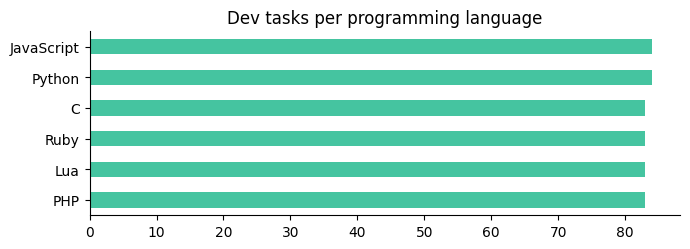

In [5]:
#@title 🧭 Detect the programming language
PL_NAME = {'python': '🐍 Python', 'javascript': '🟨 JavaScript', 'c': '⚙️ C', 'php': '🐘 PHP', 'ruby': '💎 Ruby', 'lua': '🌙 Lua'}

def detect_pl(prompt):
    lines = [l for l in prompt.strip().splitlines() if l.strip()]
    if lines[0].startswith('def ') and lines[0].rstrip().endswith(':'):
        return 'python'                        # Python: signature first, docstring after
    last = lines[-1].strip()
    if last.startswith('def '):
        return 'ruby'
    if last.startswith('function '):
        if '$' in last or re.search(r'\)\s*:\s*\??\w+\s*\{$', last):
            return 'php'
        return 'javascript' if last.endswith('{') else 'lua'
    return 'c'

hits = sum(detect_pl(r['prompt']) == REF_TRIAL[r['task_id']]['pl'] for r in trial)
print(f'🎯 language detection on trial: {hits}/{len(trial)} correct')
counts = pd.Series([PL_NAME[detect_pl(r['prompt'])].split(' ', 1)[1] for r in dev]).value_counts()   # chart fonts have no emoji
ax = counts.plot.barh(figsize=(7, 2.6), color='#45c4a0'); ax.invert_yaxis(); ax.set_title('Dev tasks per programming language')
ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.show()

## 📏 3 · The metric: Pass@1

$$\text{Pass@1} \;=\; \frac{\text{tasks whose solution passes \textbf{all} its test cases}}{\text{all tasks}}$$

* **One solution per task**, no partial credit: one failing test case fails the task. ❌
* Each task has **5 test cases**. The dev and test files show 2; the other 3 are hidden 🙈, and all 5 are scored.
* Every solution runs in a sandbox: **1 s of CPU time**, 512 MB of memory, no network, no extra files, standard library only. Infinite loops are cut at 1 s. ⏱️
* The leaderboard also shows Pass@1 for each **language class** (Joshi et al., 2020) and each **programming language**; the ranking uses overall Pass@1. 🏆

The helper below runs the **official scorer** on a set of solutions. On the trial set it knows all 5 tests, so you get the exact score CodaBench would give.

In [6]:
#@title 📏 The official scorer, as a helper
def score(solutions, tasks=None, workdir='run'):
    """Score {task_id: solution} on trial tasks with the official scorer. Returns (scores, outcome per task)."""
    tasks = tasks or list(REF_TRIAL)
    shutil.rmtree(workdir, ignore_errors=True)
    os.makedirs(f'{workdir}/ref'); os.makedirs(f'{workdir}/res')
    with open(f'{workdir}/ref/reference.jsonl', 'w') as f:
        f.writelines(json.dumps(REF_TRIAL[t]) + '\n' for t in tasks)
    json.dump({'phase': 'trial', 'detailed_results': True}, open(f'{workdir}/ref/phase.json', 'w'))
    with open(f'{workdir}/res/submission.jsonl', 'w') as f:
        f.writelines(json.dumps({'task_id': t, 'solution': solutions[t]}) + '\n' for t in tasks if t in solutions)
    r = subprocess.run([sys.executable, 'scorer/score.py', workdir, f'{workdir}/out'], capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(r.stdout + r.stderr)
    s = json.load(open(f'{workdir}/out/scores.json'))
    html_ = open(f'{workdir}/out/detailed_results.html').read()
    outcome = dict(re.findall(r'<tr><td>(T1-[a-z]+-\d+)</td><td class="\w+">([a-z ]+)</td></tr>', html_))
    return s, outcome

def card(title, value, sub='', dark=False):
    bg, fg, bd = ('#16202f', '#fff', '#16202f') if dark else ('#fff', '#16202f', '#d0d7de')
    return (f'<div style="padding:12px 18px;border-radius:14px;background:{bg};color:{fg};border:1px solid {bd};min-width:110px">'
            f'<div style="font-size:11px;letter-spacing:.04em;opacity:.7">{title}</div>'
            f'<div style="font-size:28px;font-weight:700">{value}</div><div style="font-size:11px;opacity:.6">{sub}</div></div>')

def show_scores(s, label):
    pls = ''.join(card(PL_NAME[p].split(' ', 1)[1].upper(), f'{s[p]:.1f}', PL_NAME[p].split(' ')[0]) for p in PL_NAME)
    cls = ''.join(card(f'CLASS {k}', f'{s[f"tier_{k}"]:.1f}') for k in range(4) if f'tier_{k}' in s)
    main = card('PASS@1 · ' + label, '%.1f%%' % s['score'], '', True)
    display(HTML(f'<div style="display:flex;flex-wrap:wrap;gap:10px;margin:8px 0">{main}{pls}{cls}</div>'))

In [7]:
#@title ✅ Sanity check: the reference solutions score 100%
gold = {r['task_id']: r['canonical_solution'] for r in trial}
s, _ = score(gold); show_scores(s, 'reference solutions')
broken = [PL_NAME[p] for p in PL_NAME if s[p] < 100]
assert not broken, f'🚫 These toolchains do not work yet: {broken}. Run the setup cell again.'
print('✅ all six languages run: the scorer is ready')
s, _ = score({t: '' for t in gold}); print(f'🙃 empty submission → Pass@1 {s["score"]:.1f}%')

✅ all six languages run: the scorer is ready
🙃 empty submission → Pass@1 0.0%


## 🐯 4 · Prompting TigerCoder-1B

[TigerCoder-1B](https://huggingface.co/md-nishat-008/TigerCoder-1B) is a compact code model (Gemma 3, 1B parameters) trained to write code from Bangla instructions. Here it meets 50 languages and six programming languages, many of them new to it. That is the challenge. 💪

The recipe is plain on purpose:

1. wrap the task prompt in a short **English instruction** that names the programming language;
2. ✍️ **start the answer for the model**: a code fence and the task prompt itself, so it continues *inside* the function. Left alone, TigerCoder often answers in Python, its strongest language, even when the task is in Lua or JavaScript;
3. let the model continue **greedily** (one attempt per task, as Pass@1 counts) until it closes the code block;
4. add a few common imports or headers, and drop demo code.

In [8]:
#@title 🐯 Load TigerCoder-1B and define the prompt
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = 'md-nishat-008/TigerCoder-1B'
BATCH, MAX_NEW_TOKENS = 16, 512

tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = 'left'                      # left padding for batched generation
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE).cuda().eval()
print(f'🐯 {MODEL_ID}: {sum(p.numel() for p in model.parameters()) / 1e9:.2f}B parameters')

LANG = {'python': 'Python', 'javascript': 'JavaScript', 'c': 'C', 'php': 'PHP', 'ruby': 'Ruby', 'lua': 'Lua'}

def instruction(prompt, pl):
    return (f'Complete the following {LANG[pl]} function. The problem is described in the comment. '
            f'Reply with the complete function only, in one ```{pl}``` code block, '
            f'with no main function, no tests and no printing.\n\n```{pl}\n{prompt}```')

def start_of_answer(prompt, pl):
    """We write the start of the answer ourselves: a code fence and the task's own prompt. The model then
    continues inside the function, in the right language (left alone, TigerCoder drifts to Python)."""
    return f'```{pl}\n{prompt}'

@torch.inference_mode()
def generate(model, prompts, desc='generate'):
    """Greedy continuations for a list of (prompt, pl) pairs, in batches."""
    model.eval(); answers = []
    for i in tqdm(range(0, len(prompts), BATCH), desc=desc):
        texts = [tok.apply_chat_template([{'role': 'user', 'content': instruction(p, pl)}], tokenize=False,
                                         add_generation_prompt=True) + start_of_answer(p, pl)
                 for p, pl in prompts[i:i + BATCH]]
        enc = tok(texts, return_tensors='pt', padding=True, add_special_tokens=False).to(model.device)
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=tok.pad_token_id)
        answers += tok.batch_decode(out[:, enc['input_ids'].shape[1]:], skip_special_tokens=True)
    return answers

# common imports and headers the body may need: the answer starts inside the function, so it cannot add them
PREAMBLE = {'python': 'import math, re, heapq, bisect, string\nfrom collections import Counter, defaultdict, deque\n'
                      'from functools import lru_cache, reduce\nfrom itertools import *\n',
            'c': '#include <limits.h>\n#include <ctype.h>\n#include <stdint.h>\n',
            'ruby': "require 'set'\n"}

def to_solution(answer, row, pl):
    """Prompt + the model's continuation up to the closing fence, cleaned up."""
    cont = answer.split('```')[0]
    if pl == 'python':                                       # the body must be indented: drop stray text before it
        lines = cont.split('\n')
        while lines and lines[0].strip() and not lines[0].startswith((' ', '\t')):
            lines.pop(0)
        cont = '\n'.join(lines)
    code = row['prompt'] + cont
    if pl == 'python':
        code = code.split('if __name__')[0]                 # drop demo code that would run
    if pl == 'c':
        code = re.split(r'\n\s*int\s+main\s*\(', code)[0]    # the scorer brings its own main
    if pl == 'php':
        code = re.sub(r'\?>\s*$', '', code.rstrip())
    return PREAMBLE.get(pl, '') + code.strip() + '\n'

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

🐯 md-nishat-008/TigerCoder-1B: 1.00B parameters


## 🧪 5 · Step by step on trial

**Step 5a** asks the model to solve all 100 trial tasks. **Step 5b** turns the answers into solutions. **Step 5c** scores them with the official scorer, just as CodaBench would.

In [9]:
#@title 🧪 5a · Ask the model for every trial task
t0 = time.time()
trial_answers = generate(model, [(r['prompt'], detect_pl(r['prompt'])) for r in trial], 'trial')
print(f'⏱️ {len(trial)} answers in {time.time() - t0:.0f} s')
print('─' * 70, '\n🗣️ What the model wrote after the prompt we gave it:\n'); print(trial_answers[0][:1200])

trial:   0%|          | 0/7 [00:00<?, ?it/s]

⏱️ 100 answers in 204 s
────────────────────────────────────────────────────────────────────── 
🗣️ What the model wrote after the prompt we gave it:

    local teams = {}
    local team_count = 0
    local team_length = 0
    local team_length_count = 0
    local team_length_count_count = 0
    local team_length_count_count_count = 0
    local team_length_count_count_count_count = 0
    local team_length_count_count_count_count_count = 0
    local team_length_count_count_count_count_count_count = 0
    local team_length_count_count_count_count_count_count_count_count = 0
    local team_length_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_count_coun

In [10]:
#@title 🧹 5b · Turn the answers into solutions
trial_solutions = {r['task_id']: to_solution(a, r, detect_pl(r['prompt'])) for r, a in zip(trial, trial_answers)}
print('🧹 Prompt + continuation, cleaned into a solution:\n'); print(trial_solutions[trial[0]['task_id']])

🧹 Prompt + continuation, cleaned into a solution:

-- votes या कथंया छगू स्ट्रिङ धयागु छम्ह मतदातां टीमतय्त तःधंगु अक्षरं न्हापांगु थासनिसें लिपांगु थासतक्क क्रम बियातःगु खः; दक्व votes या ग्वाःहः थें हे जुइ। टीमया अक्षर व थाय् दक्वया निंति, उगु थासय् उगु अक्षर दुगु votes गुलि दु धकाः ल्याखं। टीमतयत थाय् 1 या ल्याःकथं तःधंगुनिसें चीधंगु तक्क क्रमय् तयादिसँ; थ्व थें जूसा थाय् 2, अले थाय् 3 आदि थें स्वयादिसँ। दक्व थाय् स्वयाः नं थें जूगु टीमतयत वर्णक्रमं तयादिसँ। क्रम जूगु टीम अक्षर छगू स्ट्रिङ रूपय् लित बिउ।
--
-- दसु: rank_teams({"ABCDE", "ABCDE", "ABCDE", "EABCD", "DEABC"}) == "AEDBC"
function rank_teams(votes)
    local teams = {}
    local team_count = 0
    local team_length = 0
    local team_length_count = 0
    local team_length_count_count = 0
    local team_length_count_count_count = 0
    local team_length_count_count_count_count = 0
    local team_length_count_count_count_count_count = 0
    local team_length_count_count_count_count_count_count = 0
    local team_length_coun

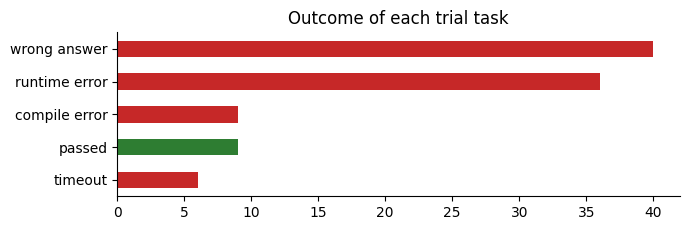

In [11]:
#@title 📊 5c · Score the trial solutions
s_trial, outcome = score(trial_solutions)
show_scores(s_trial, 'TigerCoder-1B, trial')
oc = pd.Series(outcome).value_counts()
ax = oc.plot.barh(figsize=(7, 2.4), color=['#2e7d32' if k == 'passed' else '#c62828' for k in oc.index])
ax.invert_yaxis(); ax.set_title('Outcome of each trial task'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 🔬 6 · What passed, what failed?

Reading failures is the fastest way to improve. Each outcome has a reason: **wrong answer** (the logic or the output format), **runtime error** (a crash), **compile error** (C), **timeout** (over 1 s of CPU).

In [12]:
#@title 🔬 Show one passed and two failed tasks
def show_task(tid, sol):
    r = next(x for x in trial if x['task_id'] == tid)
    color = '#2e7d32' if outcome[tid] == 'passed' else '#c62828'
    display(HTML(f"""<div style="border-left:5px solid {color};padding:6px 14px;margin:10px 0">
    <b>{tid}</b> · {PL_NAME[detect_pl(r['prompt'])]} · <span style="color:{color}"><b>{outcome[tid]}</b></span>
    <details><summary>📝 prompt</summary><pre style="white-space:pre-wrap;font-size:12px">{r['prompt']}</pre></details>
    <details open><summary>🤖 solution</summary><pre style="font-size:12px">{sol}</pre></details>
    <details><summary>✅ reference</summary><pre style="font-size:12px">{r['canonical_solution']}</pre></details></div>"""))

passed = [t for t, o in outcome.items() if o == 'passed']
failed = [t for t, o in outcome.items() if o != 'passed']
for t in passed[:1] + failed[:2]:
    show_task(t, trial_solutions[t])

🔭 **Small model, small sample.** These scores come from TigerCoder-1B, a model with 1 billion parameters, given a plain prompt and measured on 100 trial tasks. Larger models will very likely score higher. Treat this run as the starting point to beat.

### 💡 Where to go from here

<details>
<summary><b>💡 Ideas worth a try (open when you are ready)</b></summary>

* 🧪 **Use the two visible tests.** Every dev and test task shows 2 of its 5 tests. Sample several answers (`do_sample=True`), run them on the visible tests, and keep one that passes. The harness in `scorer/lc_harness.py` can run a task once you give it a signature; the types can be read from the test values.
* 🔁 **Repair loop.** When a solution fails a visible test, show the model the error or the wrong output and ask again.
* 📚 **Few-shot.** Put one or two solved trial tasks in the same programming language into the prompt.
* 🌍 **Language.** The descriptions come in 50 languages and TigerCoder knows Bangla and English best. Translating the description first can help, but keep every quoted text and every argument name exactly as written: the code must match them.
* 🧩 **Conventions.** Lua tables start at 1; C returns `malloc`'d arrays and sets `*out_len`; PHP arrays are re-indexed. Say so in the instruction.
* ✂️ **Length.** `MAX_NEW_TOKENS` cuts long answers; a cut-off answer has no closing code fence.
* 🔁 **No repetition penalty.** `repetition_penalty > 1` punishes every token already in the context, and the prompt is full of the argument names, keywords and indentation the code must reuse. We leave it at 1.0.
* 🦾 **Bigger models.** Any model or tool is allowed, as long as your system paper describes it.
</details>

## 📝 7 · Solve the dev set

Same prompt, same model, now on the 500 dev tasks. On a T4 this takes about 15–20 minutes. ☕

In [13]:
#@title 📝 Solve the 500 dev tasks
t0 = time.time()
dev_answers = generate(model, [(r['prompt'], detect_pl(r['prompt'])) for r in dev], 'dev')
dev_solutions = {r['task_id']: to_solution(a, r, detect_pl(r['prompt'])) for r, a in zip(dev, dev_answers)}
print(f'⏱️ {len(dev)} dev solutions in {(time.time() - t0) / 60:.1f} min')

dev:   0%|          | 0/32 [00:00<?, ?it/s]

⏱️ 500 dev solutions in 16.8 min


## 📤 8 · Write, check and zip the dev submission

CodaBench takes a **`.zip`** with one file, **`submission.jsonl`**: one line per task, `{"task_id": ..., "solution": ...}`. The scorer's **format check** catches the problems that would make CodaBench reject the file. Run it every time: CodaBench does not show you why a file was rejected. 🕵️

In [14]:
#@title 📤 Write, check and download submission.zip
with open('submission.jsonl', 'w', encoding='utf-8') as f:
    for r in dev:
        f.write(json.dumps({'task_id': r['task_id'], 'solution': dev_solutions[r['task_id']]}, ensure_ascii=False) + '\n')
with zipfile.ZipFile('submission.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    z.write('submission.jsonl')
print(sh(f'{sys.executable} scorer/score.py --check submission.zip dev.jsonl'))
print(f'📦 submission.zip: {os.path.getsize("submission.zip") / 1024:.0f} KB, {len(dev)} solutions')
try:
    from google.colab import files; files.download('submission.zip')
except Exception:
    print('💾 Download submission.zip from the Files panel on the left.')

Format OK: 500 solutions.
missing (scored as failed):        0
unknown task_id (ignored):         0
over 20 KB (rejected task):        0
uses an lc_ name (rejected task):  0
📦 submission.zip: 149 KB, 500 solutions


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 🚀 9 · Submit on CodaBench

1. Open [**the CodaBench competition**](https://www.codabench.org/competitions/18470/) and click **Register** (approval is automatic).
2. Go to **My Submissions** and pick the **Development** phase (the **Test** phase opens on Jan 8, 2027).
3. Fill in **Team name** and **Affiliation**: both appear on the leaderboard. Use the same team name every time.
4. Leave **Submit as** on **Yourself**. One CodaBench account per team ⚠️: submitting for the same team from several accounts can get the team disqualified.
5. Upload **`submission.zip`** and wait for **Finished**. Your Pass@1 appears on the [leaderboard](https://www.codabench.org/competitions/18470/#/results-tab), and the website's [leaderboard](https://langcode2027.github.io/task1/leaderboard/) picks it up at midnight EST. 🎉

Limits: 10 submissions a day and 300 in total in the Development phase; 3 a day and 10 in total in the Test phase. Failed submissions do not count.

❓ Questions? Ask in the [**Forum**](https://www.codabench.org/competitions/18470/#/forum) of the competition.

## 🧯 Common errors

| What you see | Why | Fix |
|---|---|---|
| 🚫 *No GPU found* | The runtime has no GPU | Runtime → Change runtime type → T4 GPU |
| 💥 *CUDA out of memory* | Batch too large | Lower `BATCH` and run the generation cell again |
| ❌ Status **Failed** on CodaBench | The file broke a format rule | Run the format check cell and fix what it reports |
| 🙈 Many *missing* tasks | Solutions not written for every `task_id` | Write one line for every dev task |
| ⏱️ Many *timeout* outcomes | Slow or looping code | Each task gets 1 s of CPU time; check loops and recursion |
| ⚙️ C tasks fail to compile | A `main` function, or a different signature | Keep the signature of the prompt; no `main` |
| 🌙 Lua or ⚙️ C answers look wrong | Language conventions | Lua tables start at 1; C returns a `malloc`'d array and sets `*out_len`, as the prompt's signature shows |